# Red Wine Quality Prediction

Classify red wines as **Low**, **Medium** or **High** quality from their physicochemical properties (UCI Wine Quality dataset).

**Setup:** `pip install -r requirements.txt`, then place `winequality-red.csv` in a `data/` folder (see README).

## 1. Load and explore the data

In [2]:
import pandas as pd

# Download winequality-red.csv (see README) and place it in the data/ folder
df = pd.read_csv("winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print("Dataset Shape:", df.shape)

print("\n Column Names:")
print(df.columns.tolist())

print('\n Data types:')
print(df.dtypes)

Dataset Shape: (1599, 12)

 Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

 Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [4]:
display(df.head())


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
display(df.tail())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [6]:
print("Missing values:",df.isnull().sum())

Missing values: fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 240


In [8]:
df.describe().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


In [9]:
quality_counts= df["quality"].value_counts().sort_index()

print("Wine count for each quality score:", quality_counts)

Wine count for each quality score: quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


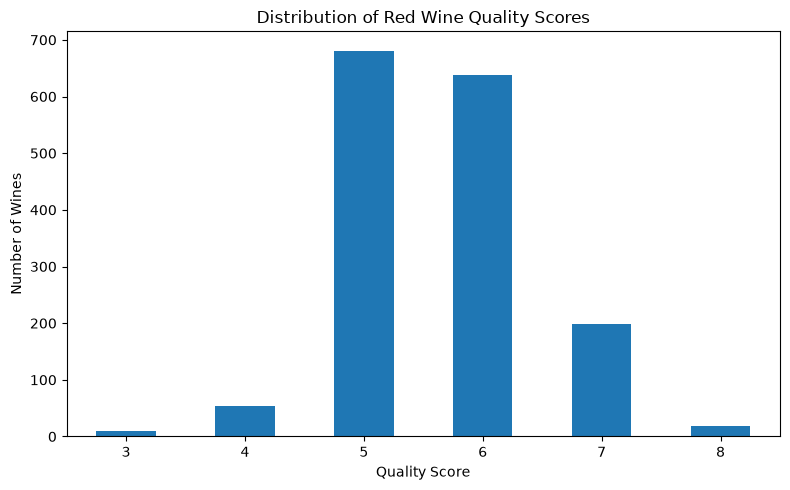

In [10]:
import matplotlib.pyplot as plt

quality_counts.plot(kind='bar', figsize=(8,5))
plt.xlabel('Quality Score')
plt.ylabel('Number of Wines')
plt.xticks(rotation=0)
plt.title('Distribution of Red Wine Quality Scores')
plt.tight_layout()
plt.show()

## 2. Remove duplicates

In [11]:
df_unique = df.drop_duplicates()

print("Original dataset:", df.shape)
print("After removing duplicates:", df_unique.shape)

Original dataset: (1599, 12)
After removing duplicates: (1359, 12)


In [12]:
print("Original quality distribution:")
print(df["quality"].value_counts().sort_index())

Original quality distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [13]:
print("Quality distribution after removing duplicates:")
print(df_unique["quality"].value_counts().sort_index())

Quality distribution after removing duplicates:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


## 3. Create the quality categories and split the data

- Low: score ≤ 4
- Medium: score 5–6
- High: score ≥ 7

In [14]:
df_clean = df.drop_duplicates().copy()

def categorize_quality(score):
  if score <= 4:
    return "Low"
  elif score <= 6:
    return "Medium"
  else:
    return "High"

df_clean["quality_category"] =(
    df_clean['quality'].apply(categorize_quality)
)

print("Dataset shape:", df_clean.shape)
print("\n Quality category counts:", df_clean['quality_category'].value_counts())
print("\n Quality category percentages:", (df_clean['quality_category'].value_counts(normalize=True) * 100).round(2))

Dataset shape: (1359, 13)

 Quality category counts: quality_category
Medium    1112
High       184
Low         63
Name: count, dtype: int64

 Quality category percentages: quality_category
Medium    81.82
High      13.54
Low        4.64
Name: proportion, dtype: float64


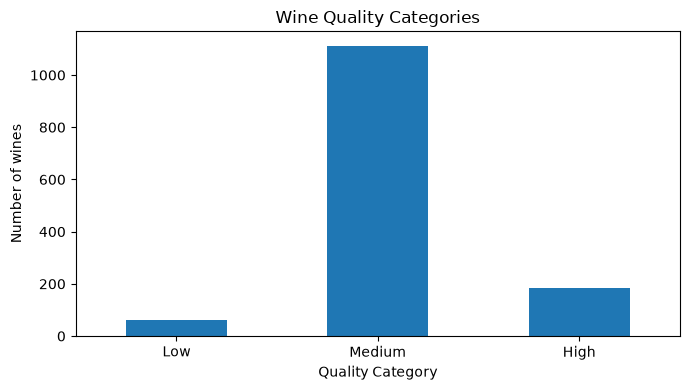

In [15]:
df_clean["quality_category"].value_counts().reindex(
    ["Low", "Medium", "High"]
).plot(kind="bar", figsize=(7,4))

plt.title("Wine Quality Categories")
plt.xlabel("Quality Category")
plt.ylabel("Number of wines")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection  import train_test_split

X = df_clean.drop(columns=["quality", "quality_category"])

y = df_clean["quality_category"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\n Training category distribution:", y_train.value_counts())
print("\nTesting category distribution:", y_test.value_counts())

Training Features: (1087, 11)
Testing Features: (272, 11)

 Training category distribution: quality_category
Medium    890
High      147
Low        50
Name: count, dtype: int64

Testing category distribution: quality_category
Medium    222
High       37
Low        13
Name: count, dtype: int64


## 4. Baseline: Logistic Regression

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [18]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

In [19]:
model.fit(X_train, y_train)
print("Model training completed successfully")

Model training completed successfully


d:\Projects\Red_Wine_Quality_Predictor\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Model accuracy: 0.6066176470588235

 Classification Report:
              precision    recall  f1-score   support

         Low       0.16      0.85      0.27        13
      Medium       0.95      0.55      0.70       222
        High       0.42      0.84      0.56        37

    accuracy                           0.61       272
   macro avg       0.51      0.75      0.51       272
weighted avg       0.84      0.61      0.66       272



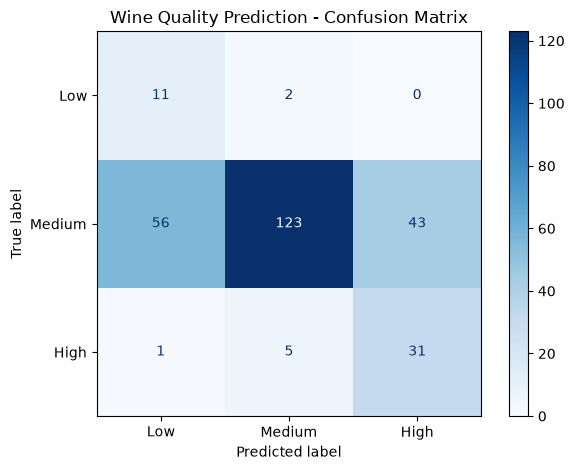

In [20]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Model accuracy:", accuracy)

print("\n Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

display.plot(cmap="Blues")
plt.title("Wine Quality Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:

print("Full cleaned dataset:")
print(y.value_counts().sort_index())

print("\nTraining set:")
print(y_train.value_counts().sort_index())

print("\nTesting set:")
print(y_test.value_counts().sort_index())

print("\nActual test labels:")
print(y_test.unique())

print("\nPredicted labels:")
print(model.classes_)

Full cleaned dataset:
quality_category
High       184
Low         63
Medium    1112
Name: count, dtype: int64

Training set:
quality_category
High      147
Low        50
Medium    890
Name: count, dtype: int64

Testing set:
quality_category
High       37
Low        13
Medium    222
Name: count, dtype: int64

Actual test labels:
<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

Predicted labels:
['High' 'Low' 'Medium']


## 5. Tree-based models

In [22]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create a Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict the test data
rf_pred = rf_model.predict(X_test)

# Evaluate the model
print(f"Random Forest Accuracy: {accuracy_score(y_test, rf_pred):.2%}")

print("\nRandom Forest Classification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)


Random Forest Accuracy: 81.99%

Random Forest Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.84      0.96      0.90       222
        High       0.64      0.24      0.35        37

    accuracy                           0.82       272
   macro avg       0.49      0.40      0.42       272
weighted avg       0.77      0.82      0.78       272



Predicted category counts:
3 Low
255 Medium
14 High


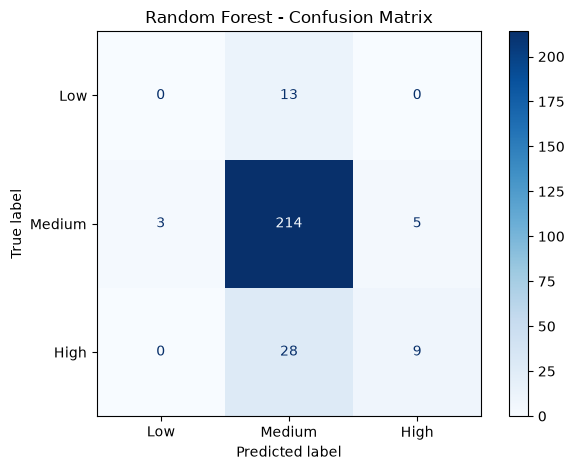

In [23]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Predicted category counts:")
print(rf_model.predict(X_test).tolist().count("Low"), "Low")
print(rf_model.predict(X_test).tolist().count("Medium"), "Medium")
print(rf_model.predict(X_test).tolist().count("High"), "High")

cm_rf = confusion_matrix(
    y_test,
    rf_pred,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [24]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Give minority categories stronger weights
custom_rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight={
        "Low": 5,
        "Medium": 1,
        "High": 2
    },
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
custom_rf_model.fit(X_train, y_train)

# Make predictions
custom_rf_pred = custom_rf_model.predict(X_test)

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, custom_rf_pred):.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        custom_rf_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)

Accuracy: 82.35%

Classification Report:
              precision    recall  f1-score   support

         Low       0.50      0.15      0.24        13
      Medium       0.86      0.94      0.90       222
        High       0.54      0.35      0.43        37

    accuracy                           0.82       272
   macro avg       0.63      0.48      0.52       272
weighted avg       0.80      0.82      0.80       272



In [25]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

# Train
gb_model.fit(X_train, y_train)

# Predict
gb_pred = gb_model.predict(X_test)

# Evaluate
print(f"Gradient Boosting Accuracy: {accuracy_score(y_test, gb_pred):.2%}")

print("\nGradient Boosting Classification Report:")
print(
    classification_report(
        y_test,
        gb_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)


Gradient Boosting Accuracy: 81.25%

Gradient Boosting Classification Report:
              precision    recall  f1-score   support

         Low       0.20      0.08      0.11        13
      Medium       0.85      0.93      0.89       222
        High       0.54      0.38      0.44        37

    accuracy                           0.81       272
   macro avg       0.53      0.46      0.48       272
weighted avg       0.78      0.81      0.79       272



## 6. Compare all models

In [26]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": model,
    "Random Forest": rf_model,
    "Custom Random Forest": custom_rf_model,
    "Gradient Boosting": gb_model
}

results = []

for name, clf in models.items():
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions,
            labels=["Low", "Medium", "High"],
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions,
            labels=["Low", "Medium", "High"],
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            labels=["Low", "Medium", "High"],
            average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print(
    comparison_df.sort_values(
        by="Macro F1", ascending=False
    ).round(3).to_string(index=False)
)


               Model  Accuracy  Macro Precision  Macro Recall  Macro F1
Custom Random Forest     0.824            0.633         0.482     0.520
 Logistic Regression     0.607            0.509         0.746     0.510
   Gradient Boosting     0.812            0.531         0.461     0.482
       Random Forest     0.820            0.494         0.402     0.417


## 7. Handle class imbalance with SMOTE

SMOTE is applied to the training data only. The test set stays untouched.

In [27]:

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Oversample only the training data
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Original training distribution:")
print(y_train.value_counts())

print("\nTraining distribution after SMOTE:")
print(y_train_smote.value_counts())

# Train a new Random Forest on the balanced data
smote_rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

smote_rf_model.fit(X_train_smote, y_train_smote)

# Evaluate on the original, untouched test set
smote_pred = smote_rf_model.predict(X_test)

print(
    f"\nSMOTE Random Forest Accuracy: "
    f"{accuracy_score(y_test, smote_pred):.2%}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        smote_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)

Original training distribution:
quality_category
Medium    890
High      147
Low        50
Name: count, dtype: int64

Training distribution after SMOTE:
quality_category
Medium    890
High      890
Low       890
Name: count, dtype: int64

SMOTE Random Forest Accuracy: 75.74%

Classification Report:
              precision    recall  f1-score   support

         Low       0.33      0.38      0.36        13
      Medium       0.89      0.80      0.85       222
        High       0.40      0.62      0.48        37

    accuracy                           0.76       272
   macro avg       0.54      0.60      0.56       272
weighted avg       0.80      0.76      0.77       272



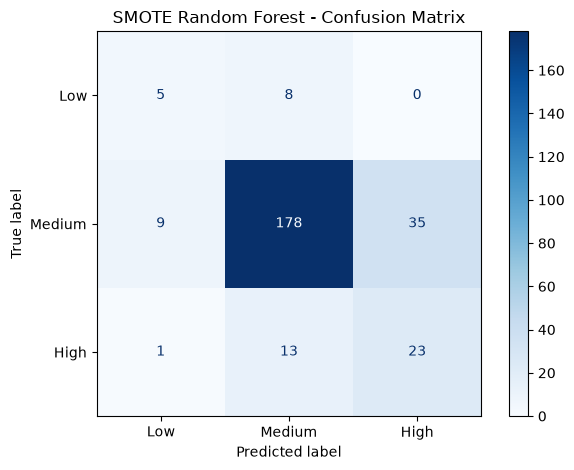

In [28]:

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

cm_smote = confusion_matrix(
    y_test,
    smote_pred,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Blues")
plt.title("SMOTE Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


## 8. Feature importance and chemical differences between categories

             Feature  Importance
             alcohol    0.170648
           sulphates    0.164420
    volatile acidity    0.160838
total sulfur dioxide    0.096833
         citric acid    0.069323
 free sulfur dioxide    0.064496
             density    0.062719
                  pH    0.056266
      residual sugar    0.053533
           chlorides    0.051999
       fixed acidity    0.048926


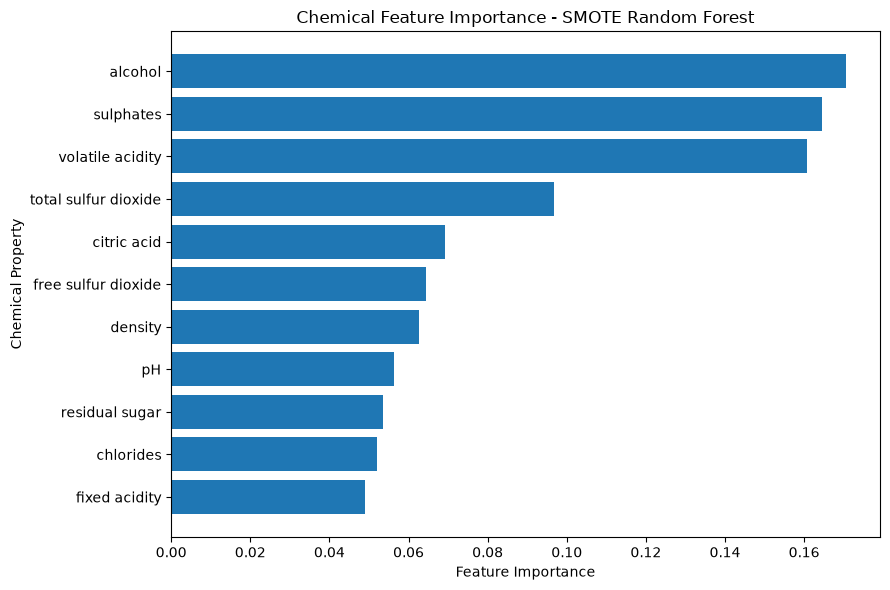

In [29]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance scores
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": smote_rf_model.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.to_string(index=False))

# Plot the results
plt.figure(figsize=(9, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Chemical Property")
plt.title("Chemical Feature Importance - SMOTE Random Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


Average chemical properties by quality category:
quality_category        High     Low  Medium
fixed acidity          8.820   7.871   8.251
volatile acidity       0.406   0.724   0.539
citric acid            0.373   0.174   0.261
residual sugar         2.704   2.685   2.484
chlorides              0.076   0.096   0.090
free sulfur dioxide   13.973  12.063  16.428
total sulfur dioxide  35.359  34.444  49.425
density                0.996   0.997   0.997
pH                     3.289   3.384   3.309
sulphates              0.746   0.592   0.648
alcohol               11.553  10.216  10.259


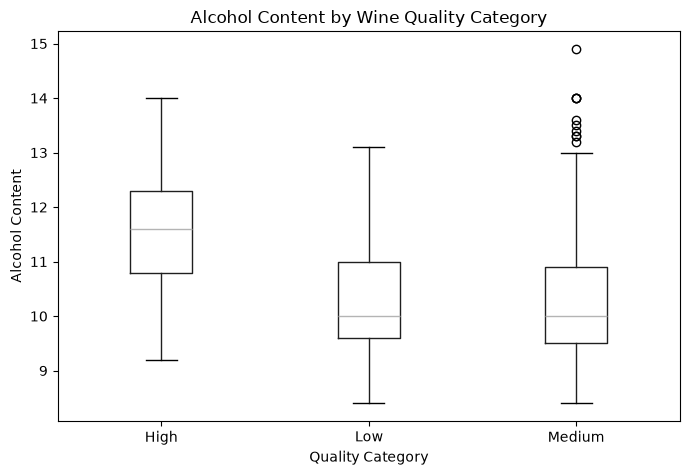

In [30]:

# Compare average chemical measurements by quality category
category_summary = df_clean.groupby("quality_category")[
    X.columns
].mean().round(3)

print("Average chemical properties by quality category:")
print(category_summary.T)

# Visualize alcohol content by category
import matplotlib.pyplot as plt

df_clean.boxplot(
    column="alcohol",
    by="quality_category",
    grid=False,
    figsize=(7, 5)
)

plt.title("Alcohol Content by Wine Quality Category")
plt.suptitle("")
plt.xlabel("Quality Category")
plt.ylabel("Alcohol Content")
plt.tight_layout()
plt.show()

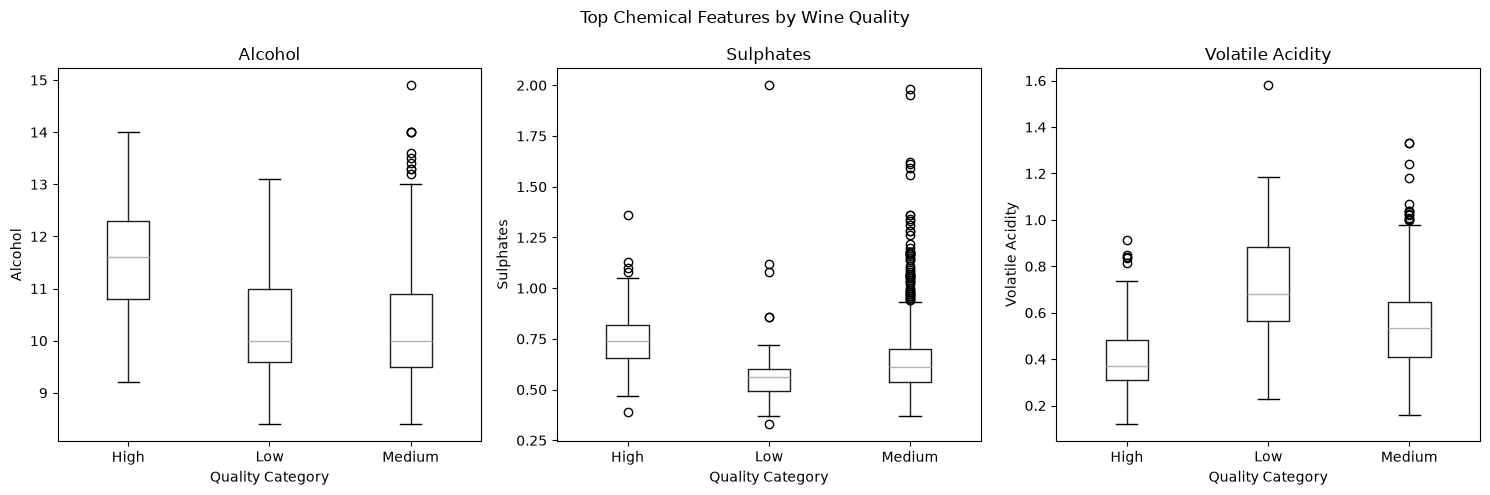

In [31]:

import matplotlib.pyplot as plt

top_features = [
    "alcohol",
    "sulphates",
    "volatile acidity"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, feature in zip(axes, top_features):
    df_clean.boxplot(
        column=feature,
        by="quality_category",
        ax=ax,
        grid=False
    )
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Quality Category")
    ax.set_ylabel(feature.replace("_", " ").title())

plt.suptitle("Top Chemical Features by Wine Quality")
plt.tight_layout()
plt.show()

## 9. Cross-validation and final model

SMOTE sits inside the pipeline, so it is applied to training folds only and never leaks into validation data.

In [32]:

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_model = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "macro_recall": "recall_macro"
    },
    n_jobs=-1
)

print(f"Mean CV Accuracy: {scores['test_accuracy'].mean():.3f}")
print(f"Mean CV Macro F1: {scores['test_macro_f1'].mean():.3f}")
print(f"Mean CV Macro Recall: {scores['test_macro_recall'].mean():.3f}")

Mean CV Accuracy: 0.755
Mean CV Macro F1: 0.522
Mean CV Macro Recall: 0.561


In [33]:

# Train the final candidate pipeline on the full training set
cv_model.fit(X_train, y_train)

print("Final candidate model trained.")

# Evaluate once on the untouched test set
final_pred = cv_model.predict(X_test)

from sklearn.metrics import classification_report, accuracy_score

print(f"\nTest Accuracy: {accuracy_score(y_test, final_pred):.2%}")

print("\nFinal Test Classification Report:")
print(
    classification_report(
        y_test,
        final_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)


Final candidate model trained.

Test Accuracy: 75.74%

Final Test Classification Report:
              precision    recall  f1-score   support

         Low       0.33      0.38      0.36        13
      Medium       0.89      0.80      0.85       222
        High       0.40      0.62      0.48        37

    accuracy                           0.76       272
   macro avg       0.54      0.60      0.56       272
weighted avg       0.80      0.76      0.77       272



## 10. Save the model and predict on a new wine

In [34]:

import joblib

# Save the complete trained pipeline
joblib.dump(cv_model, "wine_quality_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [35]:
import pandas as pd

new_wine = pd.DataFrame([{
    "fixed acidity": 7.4,
    "volatile acidity": 0.30,
    "citric acid": 0.40,
    "residual sugar": 2.0,
    "chlorides": 0.060,
    "free sulfur dioxide": 20.0,
    "total sulfur dioxide": 45.0,
    "density": 0.9955,
    "pH": 3.25,
    "sulphates": 0.70,
    "alcohol": 11.5
}])

print(new_wine)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4               0.3          0.4             2.0       0.06   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 20.0                  45.0   0.9955  3.25        0.7   

   alcohol  
0     11.5  


In [36]:
predicted_category = cv_model.predict(new_wine)[0]

# Get prediction probabilities
probabilities = cv_model.predict_proba(new_wine)[0]

print("Predicted Wine Quality Category:", predicted_category)

print("\nModel probability estimates:")
for category, probability in zip(
    cv_model.classes_, probabilities
):
    print(f"{category}: {probability:.2%}")


Predicted Wine Quality Category: High

Model probability estimates:
High: 71.71%
Low: 1.11%
Medium: 27.18%
